# Laplace–Beltrami features: combinations, selection, ACC, AUC and the TDSC-ABUS benchmark

**Questions.** Using all Laplace–Beltrami features, their combinations and feature selection, across many classifiers, what ACC and AUC can be reached? Do size and classical features lift both above 0.80? Where does that place on the TDSC-ABUS challenge's classification board?

**The answer in one table** is in Section 4. How to rerun: [`docs/reproductions/lb-feature-evaluation.md`](../docs/reproductions/lb-feature-evaluation.md).

## 1. Protocol

The Test split gives one clean answer, so the work had two stages:

1. **Freeze, Train+Validation only.** Compare 17 classifiers and 10 feature sets, with optional univariate filters (510 combinations). A rule, fixed in advance, picks the highest mean of cross-validated AUC and ACC, over all features and over LB features only. Those two winners are the primary results. Everything is saved to `results/lb-evaluation/frozen.json`, whose checksum was recorded before Test was read: `02c488e3…5dde`.
2. **Evaluate, once on Test.** Models are refitted on all 130 lesions and scored on the 70 Test lesions. All 510 are reported, so the best on Test can be seen for what it is: the maximum of 510 tries.

The benchmark is `abus_classification/challenge.py`: ACC at $p\ge0.5$, AUC, malignant positive, placed on the published board as if each model had entered alone. **All features use ground-truth masks**, so these are not comparable with teams that located lesions themselves, and they are classification-only results. Logistic and SVM fits have no random seed, so the 3-seed protocol applies only in form here.

**LB features:** Hersch ratio, Shape-DNA, heat trace, HKS, WKS, GPS, tips and harmonics. **Classical:** size, spiculation, intensity, classical shape, elongation and sphericity.

## 2. LB features on Train+Validation

Each group and combination, logistic regression, 20 repeats of five-fold CV. Combinations are exploratory: their best is favoured by chance.

In [1]:
import sys, json; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, trimesh
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from abus_classification import challenge, lb_classification as lc, lb_evaluation as le
from abus_classification.utils.mesh import draw_mesh
BLUE, ORANGE, AQUA, INK, GRID, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df", "#b9b7b0"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "axes.grid": True, "grid.color": GRID, "font.size": 10})
O = "../results/lb-evaluation/"; frozen = json.load(open(O + "frozen.json")); sel = json.load(open(O + "selection.json")); cvg, teg = pd.read_csv(O + "grid_cv.csv"), pd.read_csv(O + "grid_test.csv"); res = pd.read_csv(O + "test_results.csv", index_col=0); bench = pd.read_csv(O + "benchmark.csv", index_col=0); preds = pd.read_csv(O + "test_predictions.csv")
display(pd.read_csv(O + "groups.csv", index_col=0).sort_values("AUC", ascending=False).round(3))
print("Best pairs:"); display(pd.read_csv(O + "pairs.csv").sort_values("AUC", ascending=False).head(5).round(3)); print("Best triples:"); display(pd.read_csv(O + "triples.csv").sort_values("AUC", ascending=False).head(5).round(3))
null_g, null_f = np.array(sel["groups"]["null"]), np.array(sel["features"]["null"])
print(f"Selection inside CV, LB groups: AUC {sel['groups']['AUC']:.3f}, ACC {sel['groups']['ACC']:.3f}; shuffled labels 95th pct AUC {np.percentile(null_g, 95):.3f}")
print(f"Selection inside CV, LB features: AUC {sel['features']['AUC']:.3f}, ACC {sel['features']['ACC']:.3f}; shuffled labels 95th pct AUC {np.percentile(null_f, 95):.3f}")
print("Chosen LB features (picked in at least 40% of folds):", frozen["sets"]["LB selected features"])

,AUC,ACC
Tips,0.675,0.632
All LB features,0.671,0.638
WKS local,0.635,0.615
Heat trace,0.602,0.598
Hersch ratio,0.594,0.599
HKS local,0.588,0.583
GPS,0.541,0.592
Harmonics,0.522,0.555
Shape-DNA,0.508,0.542


Best pairs:


,a,b,AUC,ACC
19,HKS local,Tips,0.703,0.658
15,Heat trace,Tips,0.696,0.645
4,Hersch ratio,Tips,0.689,0.653
14,Heat trace,WKS local,0.680,0.639
25,Tips,GPS,0.678,0.634


Best triples:


,groups,AUC,ACC
18,Hersch ratio + Tips + GPS,0.721,0.663
46,HKS local + WKS local + Tips,0.713,0.677
49,HKS local + Tips + GPS,0.709,0.658
40,Heat trace + WKS local + Tips,0.706,0.662
8,Hersch ratio + Heat trace + Tips,0.701,0.650


Selection inside CV, LB groups: AUC 0.647, ACC 0.613; shuffled labels 95th pct AUC 0.602
Selection inside CV, LB features: AUC 0.625, ACC 0.597; shuffled labels 95th pct AUC 0.582
Chosen LB features (picked in at least 40% of folds): ['WKS local: log p95, band 7', 'Tips: log tips, tau 0.021', 'Heat trace: log trace, tau 0.004']


## 3. Classifiers and feature sets on Train+Validation

Best score reached by each feature set and each classifier over the grid (5 repeats of five-fold CV). These are optimistic, as the "LB selected" list was chosen on the same lesions. The nested line reruns the whole search inside cross-validation, though it reuses that list, so even it is slightly generous.

In [2]:
display(cvg.groupby("set")[["AUC", "ACC"]].max().sort_values("AUC", ascending=False).round(3)); display(cvg.groupby("classifier")[["AUC", "ACC"]].max().sort_values("AUC", ascending=False).round(3))
print(f"Combinations with both AUC and ACC at 0.80 or above, cross-validated: {((cvg.AUC >= .8) & (cvg.ACC >= .8)).sum()} of {len(cvg)}")
print("The search inside cross-validation:", {k: {a: round(b, 3) for a, b in v.items()} for k, v in frozen["nested"].items()}); print("Chosen by the rule:", {k: v for k, v in frozen["named"].items() if k.startswith("Best")})

,AUC,ACC
set,,
All classical + LB selected features,0.863,0.805
All classical,0.858,0.800
All classical + all LB,0.845,0.778
Size + spiculation + Hersch ratio,0.844,0.780
Size + spiculation,0.814,0.768
Size + LB selected features,0.775,0.725
LB selected features,0.741,0.698
Size + all LB,0.730,0.680
LB selected groups,0.723,0.663


,AUC,ACC
classifier,,
Logistic C=0.1,0.863,0.803
SVM linear C=0.01,0.858,0.800
Logistic C=0.01,0.857,0.805
LDA shrinkage,0.853,0.794
Logistic C=1,0.849,0.783
SVM linear C=0.1,0.845,0.765
SVM RBF C=1,0.843,0.766
Gradient boosting,0.841,0.771
Logistic L1 C=0.5,0.840,0.762


Combinations with both AUC and ACC at 0.80 or above, cross-validated: 3 of 510
The search inside cross-validation: {'Any features': {'AUC': 0.803, 'ACC': 0.746}, 'LB features only': {'AUC': 0.682, 'ACC': 0.654}}
Chosen by the rule: {'Best overall by the rule': {'set': 'All classical + LB selected features', 'classifier': 'Logistic C=0.1', 'k': None}, 'Best LB-only by the rule': {'set': 'LB selected features', 'classifier': 'Logistic C=1', 'k': None}}


## 4. Results on Test

Frozen models, once. `Cls_Rank` places each on the challenge's classification board of 9. The first two rows are primary; the rest were named in the same frozen file.

,ACC,AUC,AUC_low,AUC_high,sensitivity,specificity,Cls_Score,Cls_Rank
Best overall by the rule,0.786,0.848,0.743,0.924,0.900,0.633,0.936,2/9
Best LB-only by the rule,0.600,0.692,0.565,0.812,0.775,0.367,0.326,6/9
Logistic: LB selected features,0.600,0.692,0.565,0.812,0.775,0.367,0.326,6/9
Logistic: LB selected groups,0.629,0.614,0.476,0.752,0.800,0.400,0.273,6/9
Logistic: All LB,0.529,0.483,0.347,0.622,0.675,0.333,0.000,9/9
Logistic: Size + LB selected features,0.671,0.723,0.605,0.844,0.800,0.500,0.542,5/9
Logistic: Size + all LB,0.571,0.544,0.403,0.679,0.675,0.433,0.067,7/9
Logistic: Size + spiculation,0.871,0.889,0.792,0.969,0.925,0.800,1.000,1/9
Logistic: Size + spiculation + Hersch ratio,0.829,0.869,0.769,0.946,0.900,0.733,0.969,1/9
Logistic: All classical,0.729,0.845,0.744,0.924,0.800,0.633,0.865,2/9


Published classification results:


,ACC,AUC
T1 SZU,0.7571,0.8892
T3 HU,0.7286,0.7733
T4 KTH,0.7429,0.7708
T10 DGIST,0.7143,0.7642
T2 POSTECH,0.6429,0.6558
T7 PR,0.6000,0.6425
T5 EPITA,0.5429,0.5775
T6 FX,0.5429,0.5675


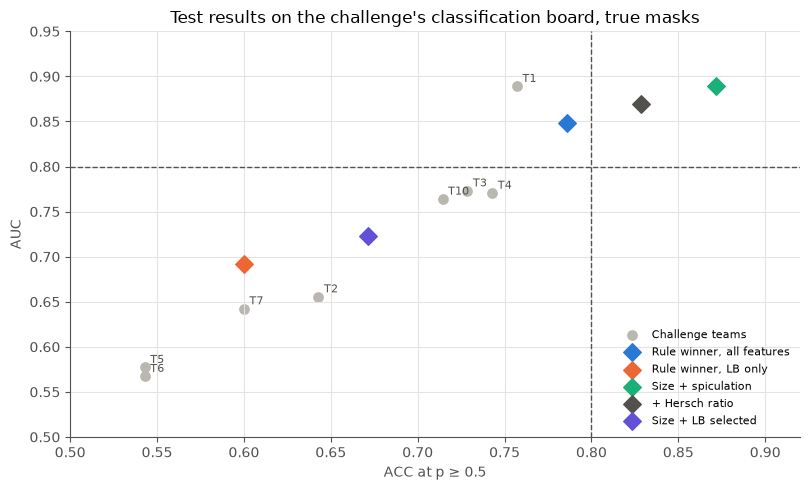

In [3]:
table = res[["set", "classifier", "ACC", "AUC", "AUC_low", "AUC_high", "sensitivity", "specificity"]].join(bench[["Cls_Score", "Cls_Rank"]]); num = ["ACC", "AUC", "AUC_low", "AUC_high", "sensitivity", "specificity", "Cls_Score"]; table[num] = table[num].astype(float).round(3); display(table.drop(columns=["set", "classifier"]))
print("Published classification results:"); display(challenge.PUBLISHED[["ACC", "AUC"]].dropna().sort_values("AUC", ascending=False))
fig, ax = plt.subplots(figsize=(8.2, 5)); pub = challenge.PUBLISHED[["ACC", "AUC"]].dropna(); ax.scatter(pub.ACC, pub.AUC, color=MUTED, s=45, label="Challenge teams")
for n, r in pub.iterrows(): ax.annotate(n.split()[0], (r.ACC, r.AUC), xytext=(4, 3), textcoords="offset points", fontsize=8, color=INK)
show = {"Best overall by the rule": ("Rule winner, all features", BLUE), "Best LB-only by the rule": ("Rule winner, LB only", ORANGE), "Logistic: Size + spiculation": ("Size + spiculation", AQUA), "Logistic: Size + spiculation + Hersch ratio": ("+ Hersch ratio", INK), "Logistic: Size + LB selected features": ("Size + LB selected", "#6250d6")}
for k, (name, c) in show.items(): ax.scatter(float(res.ACC[k]), float(res.AUC[k]), color=c, s=80, marker="D", label=name, zorder=5)
ax.axhline(.8, color=INK, lw=1, ls="--"); ax.axvline(.8, color=INK, lw=1, ls="--"); ax.set(xlabel="ACC at p ≥ 0.5", ylabel="AUC", title="Test results on the challenge's classification board, true masks", xlim=(.5, .92), ylim=(.5, .95)); ax.legend(frameon=False, fontsize=8, loc="lower right"); plt.tight_layout(); plt.savefig("../docs/assets/lb-evaluation-board.png", dpi=150); plt.show()

,AUC before,AUC after,Gain,"95% CI, low","95% CI, high"
Size + spiculation → + Hersch ratio,0.889,0.869,-0.020,-0.086,0.042
Size + spiculation → rule winner,0.889,0.848,-0.041,-0.108,0.021
LB selected → + size,0.692,0.723,0.032,-0.035,0.096


Confusion, rule winner [[TN, FP], [FN, TP]]: [[19, 11], [4, 36]] ; Size + spiculation: [[24, 6], [3, 37]]


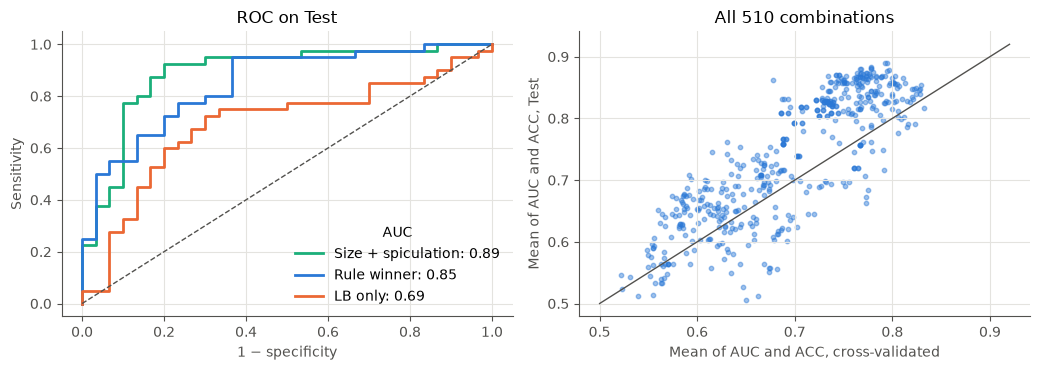

Share of the 510 with both AUC and ACC at 0.80 or above on Test: 29.6%; best of 510, chosen on Test and so biased:


,set,classifier,k,ACC,AUC,goal
430,All classical + LB selected features,Extra trees,0,0.857,0.922,0.889
433,All classical + LB selected features,Extra trees,20,0.843,0.935,0.889
429,All classical + LB selected features,Random forest,20,0.829,0.939,0.884
254,Size + spiculation,SVM linear C=0.1,0,0.871,0.893,0.882
242,Size + spiculation,Logistic C=1,0,0.871,0.889,0.880


,AUC,ACC
set,,
All classical,0.869,0.800
All classical + LB selected features,0.869,0.800
Size + spiculation,0.855,0.800
Size + spiculation + Hersch ratio,0.854,0.800
All classical + all LB,0.854,0.786
Size + all LB,0.740,0.657
Size + LB selected features,0.727,0.671
LB selected groups,0.657,0.607
LB selected features,0.646,0.600


In [4]:
y = preds.y.values; rng = np.random.default_rng(0); B = 4000
def gain(a, b):
    D = []
    while len(D) < B:
        i = rng.integers(0, 70, 70)
        if 0 < y[i].sum() < 70: D.append(roc_auc_score(y[i], preds[b].values[i]) - roc_auc_score(y[i], preds[a].values[i]))
    return {"AUC before": roc_auc_score(y, preds[a]), "AUC after": roc_auc_score(y, preds[b]), "Gain": roc_auc_score(y, preds[b]) - roc_auc_score(y, preds[a]), "95% CI, low": np.percentile(D, 2.5), "95% CI, high": np.percentile(D, 97.5)}
display(pd.DataFrame({"Size + spiculation → + Hersch ratio": gain("Logistic: Size + spiculation", "Logistic: Size + spiculation + Hersch ratio"), "Size + spiculation → rule winner": gain("Logistic: Size + spiculation", "Best overall by the rule"), "LB selected → + size": gain("Logistic: LB selected features", "Logistic: Size + LB selected features")}).T.round(3))
print("Confusion, rule winner [[TN, FP], [FN, TP]]:", confusion_matrix(y, preds["Best overall by the rule"] >= .5).tolist(), "; Size + spiculation:", confusion_matrix(y, preds["Logistic: Size + spiculation"] >= .5).tolist())
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
for k, c, name in (("Logistic: Size + spiculation", AQUA, "Size + spiculation"), ("Best overall by the rule", BLUE, "Rule winner"), ("Best LB-only by the rule", ORANGE, "LB only")):
    f_, t_, _ = roc_curve(y, preds[k]); ax[0].plot(f_, t_, color=c, lw=2, label=f"{name}: {roc_auc_score(y, preds[k]):.2f}")
ax[0].plot([0, 1], [0, 1], color=INK, lw=1, ls="--"); ax[0].set(xlabel="1 − specificity", ylabel="Sensitivity", title="ROC on Test"); ax[0].legend(frameon=False, title="AUC")
ax[1].scatter((cvg.AUC + cvg.ACC) / 2, (teg.AUC + teg.ACC) / 2, s=10, color=BLUE, alpha=.45); lim = (.5, .92); ax[1].plot(lim, lim, color=INK, lw=1); ax[1].set(xlabel="Mean of AUC and ACC, cross-validated", ylabel="Mean of AUC and ACC, Test", title="All 510 combinations")
plt.tight_layout(); plt.savefig("../docs/assets/lb-evaluation-roc.png", dpi=150); plt.show()
teg["goal"] = (teg.AUC + teg.ACC) / 2; print(f"Share of the 510 with both AUC and ACC at 0.80 or above on Test: {((teg.AUC >= .8) & (teg.ACC >= .8)).mean():.1%}; best of 510, chosen on Test and so biased:"); display(teg.sort_values("goal", ascending=False).head(5).round(3)); display(teg.groupby("set")[["AUC", "ACC"]].median().sort_values("AUC", ascending=False).round(3))

## 5. Are the visible differences real?

Shape differences between single lesions are easy to see, so this asks a narrower question: do they *separate the classes*? Below are five Train lesions per class chosen by rule, at the 5th–95th percentiles of the Hersch ratio. Both classes contain rounded and irregular lesions. Then the numbers: how far each shape measure separates the classes on all 130 lesions, and how much it overlaps.

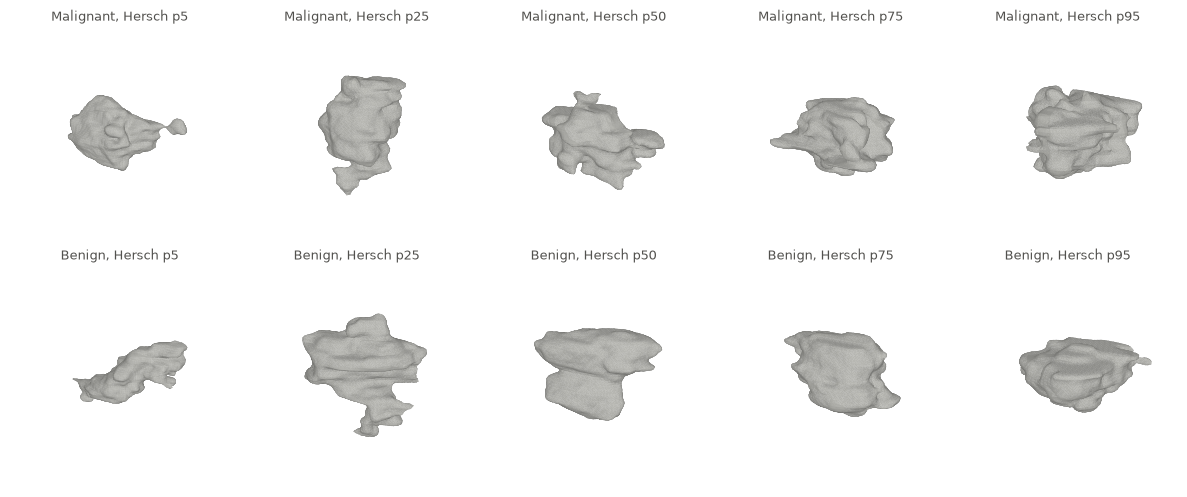

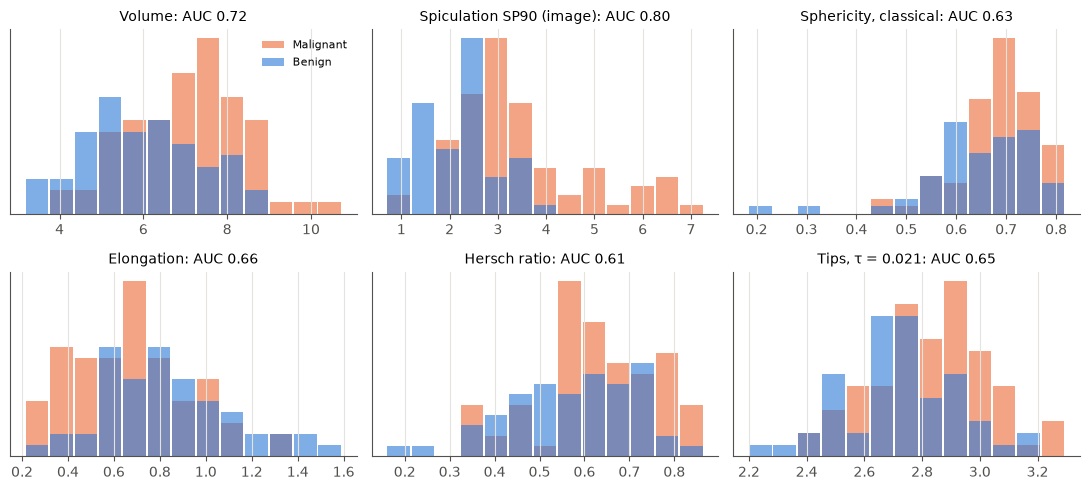

In [5]:
store = np.load("../results/lb-roundness/sample_meshes.npz"); fig = plt.figure(figsize=(12, 5))
for r_, cls in enumerate(("malignant", "benign")):
    for c_, q in enumerate((5, 25, 50, 75, 95)):
        k = f"{cls}_q{q}"; m = trimesh.Trimesh(store[k + "_vertices"].astype(float), store[k + "_faces"], process=False); ax = fig.add_subplot(2, 5, r_ * 5 + c_ + 1, projection="3d"); draw_mesh(ax, m); ax.set_title(f"{cls.capitalize()}, Hersch p{q}", fontsize=9, color=INK)
plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-classes.png", dpi=130); plt.show()
tv = lc.tv_table(); yy = tv.y.values; meas = {"Size: log volume": "Volume", "Spiculation: SP90": "Spiculation SP90 (image)", "Classical shape: SH": "Sphericity, classical", "Elongation and sphericity: log elongation": "Elongation", "Hersch ratio: lambda_1 * area / 8 pi": "Hersch ratio", "Tips: log tips, tau 0.021": "Tips, τ = 0.021"}
fig, axes = plt.subplots(2, 3, figsize=(11, 5))
for ax, (c, name) in zip(axes.ravel(), meas.items()):
    x = tv[c].values; bins = np.linspace(x.min(), x.max(), 14); ax.hist(x[yy == 1], bins, color=ORANGE, alpha=.6, rwidth=.92, label="Malignant"); ax.hist(x[yy == 0], bins, color=BLUE, alpha=.6, rwidth=.92, label="Benign"); a = roc_auc_score(yy, x); ax.set_title(f"{name}: AUC {max(a, 1 - a):.2f}", fontsize=10); ax.set_yticks([])
axes[0, 0].legend(frameon=False, fontsize=8); plt.tight_layout(); plt.savefig("../docs/assets/lb-class-overlap.png", dpi=150); plt.show()

## 6. Conclusions

- **The target is reachable with classical features, not with LB features.** The rule's winner, all classical plus selected LB features, reaches AUC 0.848 (0.743–0.924) and ACC 0.786, rank 2 of 9. So AUC clears 0.80 and ACC just misses it. Simple size + spiculation, named in the same frozen file, reaches AUC 0.889 and ACC 0.871, and ranks 1 of 9 with its Cls_Score the highest possible.
- **LB features alone do not reach it.** The rule's LB-only winner reaches AUC 0.692 (0.565–0.812) and ACC 0.600, rank 6 of 9. Using all 91 LB features at once gives AUC 0.483, which is chance: on 130 lesions that many features overfit.
- **The earlier spectral gain did not replicate.** On Train+Validation the Hersch ratio added 0.045 to size and spiculation. On Test it changes AUC from 0.889 to 0.869, with the interval in the table above. Adding the LB selected features to all classical features also lowers AUC, from 0.845 to 0.823. So no Laplace–Beltrami feature has shown independent value on held-out data.
- **Classifier choice matters less than features.** On Test, median AUC by feature set spans 0.61–0.87, and by classifier 0.74–0.85. Within classical sets, extra trees has the highest median (0.91) and RBF SVM with C = 10 the lowest (0.83). Cross-validation favoured linear models, so it would not have picked trees: tree models may suit this data, but that is a post-hoc observation to confirm on new data.
- **The best of 510 is not a result.** Extra trees on classical + LB selected features reached AUC 0.922 and ACC 0.857 on Test, but it was found by looking at Test, and it would not have been the rule's pick.
- **The rank is not a like-for-like win.** Our models use ground-truth masks and classify only; challenge teams worked from their own detections and segmentations. Spiculation in particular needs a lesion mask.
- **Visible differences are real but overlap.** Single lesions look very different, but both classes contain round and irregular lesions, so the shape measures above overlap heavily. A more visible difference between examples does not by itself mean a stronger class difference.

## 7. Open issues

- **Test has now been used.** Any further tuning against it would be biased. New models need new data, such as IIPL-3D-ABUS, or a clearly labelled post-hoc analysis.
- **Predicted masks.** A full pipeline should run these features on its own masks; `lb-stability.ipynb` suggests shape features would fall.
- **Local maps.** Models on signature maps instead of summaries are untested, and they could capture the visual impression better.